In [4]:
import Pkg
Pkg.activate("..")
Pkg.instantiate()

using CSV
using DataFrames
using Plots

  Activating project at `d:\OneDrive\Desktop\HCMUS-CNTT(TCTA)\NAM-BA-(2026-2027)\HK1\DM\projects\fim\Group 7`


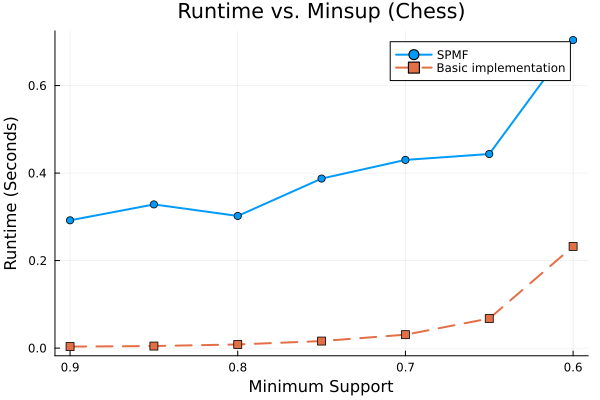

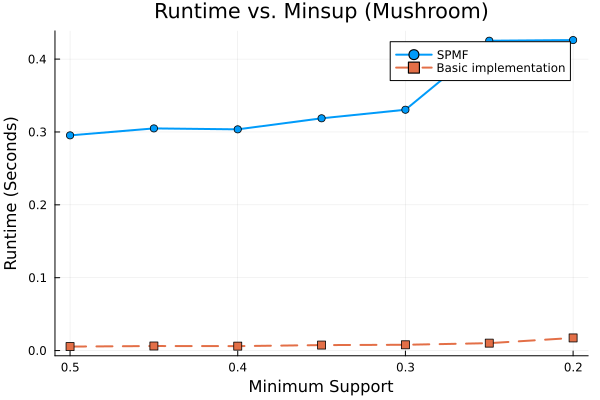

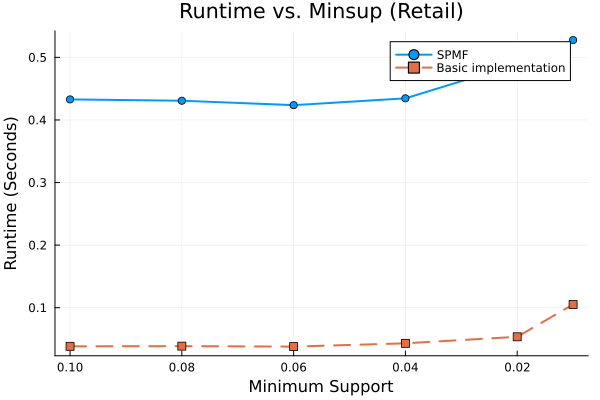

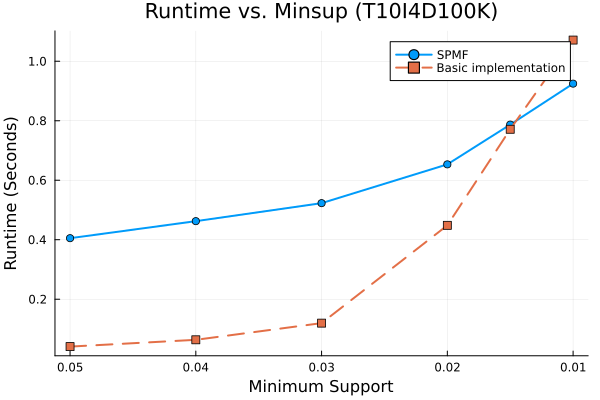

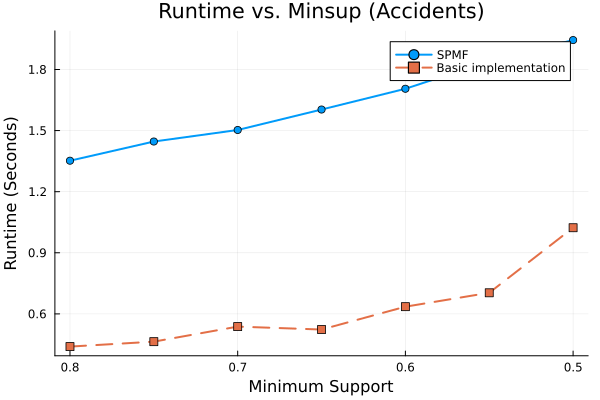

In [6]:
df = CSV.read("../data/results/exp2_runtime_vs_minsup/exp2_runtime.csv", DataFrame)

datasets = unique(df.Dataset)

for dataset in datasets
    data = filter(row -> row.Dataset == dataset, df)
    
    p = plot(data.Minsup, data.SPMF_Time_s, label="SPMF", marker=:circle, lw=2)
    plot!(p, data.Minsup, data.Base_Time_s, label="Basic implementation", marker=:square, lw=2, ls=:dash)
    
    plot!(p, 
        xflip = true,
        title = "Runtime vs. Minsup ($(uppercasefirst(dataset)))",
        xlabel = "Minimum Support",
        ylabel = "Runtime (Seconds)",
        legend = :topright,
        grid = true
    )
    
    display(p)
    savefig(p, "../data/results/exp2_runtime_vs_minsup/plot_runtime_$(dataset).png")
end